In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("customer_shopping_data.csv")

In [3]:
df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [4]:
df.tail()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
99452,I219422,C441542,Female,45,Souvenir,5,58.65,Credit Card,21/09/2022,Kanyon
99453,I325143,C569580,Male,27,Food & Beverage,2,10.46,Cash,22/09/2021,Forum Istanbul
99454,I824010,C103292,Male,63,Food & Beverage,2,10.46,Debit Card,28/03/2021,Metrocity
99455,I702964,C800631,Male,56,Technology,4,4200.00,Cash,16/03/2021,Istinye Park
99456,I232867,C273973,Female,36,Souvenir,3,35.19,Credit Card,15/10/2022,Mall of Istanbul


In [5]:
df.groupby("shopping_mall").count() #Count records by shopping mall

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date
shopping_mall,,,,,,,,,
Cevahir AVM,4991,4991,4991,4991,4991,4991,4991,4991,4991
Emaar Square Mall,4811,4811,4811,4811,4811,4811,4811,4811,4811
Forum Istanbul,4947,4947,4947,4947,4947,4947,4947,4947,4947
Istinye Park,9781,9781,9781,9781,9781,9781,9781,9781,9781
Kanyon,19823,19823,19823,19823,19823,19823,19823,19823,19823
Mall of Istanbul,19943,19943,19943,19943,19943,19943,19943,19943,19943
Metrocity,15011,15011,15011,15011,15011,15011,15011,15011,15011
Metropol AVM,10161,10161,10161,10161,10161,10161,10161,10161,10161
Viaport Outlet,4914,4914,4914,4914,4914,4914,4914,4914,4914


In [6]:
df.groupby("category").count() #Count records by product category

,invoice_no,customer_id,gender,age,quantity,price,payment_method,invoice_date,shopping_mall
category,,,,,,,,,
Books,4981,4981,4981,4981,4981,4981,4981,4981,4981
Clothing,34487,34487,34487,34487,34487,34487,34487,34487,34487
Cosmetics,15097,15097,15097,15097,15097,15097,15097,15097,15097
Food & Beverage,14776,14776,14776,14776,14776,14776,14776,14776,14776
Shoes,10034,10034,10034,10034,10034,10034,10034,10034,10034
Souvenir,4999,4999,4999,4999,4999,4999,4999,4999,4999
Technology,4996,4996,4996,4996,4996,4996,4996,4996,4996
Toys,10087,10087,10087,10087,10087,10087,10087,10087,10087


In [7]:
branch_sales = df.groupby("shopping_mall").sum(numeric_only=True)

branch_sales #Calculate total sales for each shopping mall

,age,quantity,price
shopping_mall,,,
Cevahir AVM,215474,14949,3433671.84
Emaar Square Mall,209575,14501,3390408.31
Forum Istanbul,215380,14852,3336073.82
Istinye Park,424335,29465,6717077.54
Kanyon,862280,59457,13710755.24
Mall of Istanbul,866333,60114,13851737.62
Metrocity,652968,44894,10249980.07
Metropol AVM,439086,30530,6937992.99
Viaport Outlet,212771,14716,3414019.46


In [8]:
category_sales = df.groupby("category").sum(numeric_only=True)

category_sales  #Calculate total sales by product category

,age,quantity,price
category,,,
Books,216882,14982,226977.30
Clothing,1497054,103558,31075684.64
Cosmetics,657937,45465,1848606.90
Food & Beverage,640605,44277,231568.71
Shoes,436027,30217,18135336.89
Souvenir,216922,14871,174436.83
Technology,216669,15021,15772050.00
Toys,437032,30321,1086704.64


In [9]:
branch_sales.sort_values(by="price", ascending=False).head(5) #Get top 5 performing branches

,age,quantity,price
shopping_mall,,,
Mall of Istanbul,866333,60114,13851737.62
Kanyon,862280,59457,13710755.24
Metrocity,652968,44894,10249980.07
Metropol AVM,439086,30530,6937992.99
Istinye Park,424335,29465,6717077.54


In [10]:
category_sales.sort_values(by="price", ascending=False).head(5) #Get top 5 selling categories

,age,quantity,price
category,,,
Clothing,1497054,103558,31075684.64
Shoes,436027,30217,18135336.89
Technology,216669,15021,15772050.00
Cosmetics,657937,45465,1848606.90
Toys,437032,30321,1086704.64


In [11]:
combined_sales = df.groupby(
    ["shopping_mall", "category"]
).sum(numeric_only=True)

combined_sales  #Calculate total sales for each combination of branch and product category

age  quantity       price
shopping_mall category                                    
Cevahir AVM   Books            11464       792    11998.80
              Clothing         74729      5180  1554414.40
              Cosmetics        31142      2174    88394.84
              Food & Beverage  33269      2293    11992.39
              Shoes            21211      1473   884050.41
...                              ...       ...         ...
Zorlu Center  Food & Beverage  32687      2216    11589.68
              Shoes            22949      1589   953670.13
              Souvenir         10727       716     8398.68
              Technology       10533       765   803250.00
              Toys             22395      1526    54691.84

[80 rows x 3 columns]

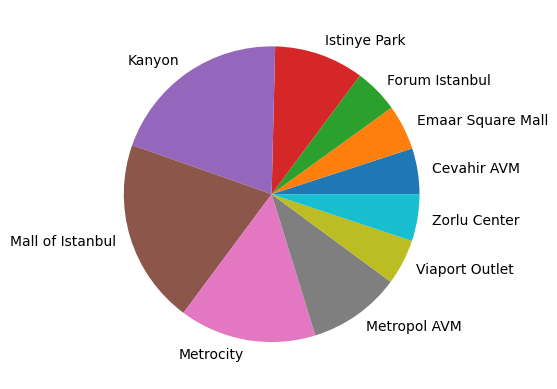

In [12]:
plt.pie(branch_sales["price"], labels=branch_sales.index)
plt.show()  #Plot sales by branch

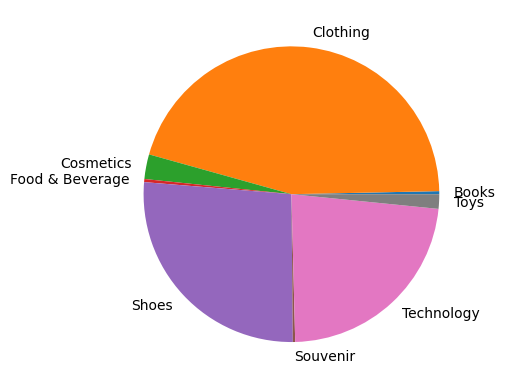

In [13]:
plt.pie(category_sales["price"], labels=category_sales.index)
plt.show() #Plot sales by product category

In [14]:
combined_pivot = df.pivot_table(
    index="shopping_mall",
    columns="category",
    values="price",
    aggfunc="sum"
)

combined_pivot  #Create pivot table

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
shopping_mall,,,,,,,,
Cevahir AVM,11998.80,1554414.40,88394.84,11992.39,884050.41,8304.84,819000.0,55516.16
Emaar Square Mall,11059.50,1511803.04,92379.52,11030.07,871446.84,8515.98,834750.0,49423.36
Forum Istanbul,11453.40,1572119.12,95225.72,10836.56,875648.03,9090.75,706650.0,55050.24
Istinye Park,20725.20,3050313.20,178741.36,23419.94,1806511.70,18369.18,1509900.0,109096.96
Kanyon,44980.35,6155541.04,372242.30,45474.85,3640031.05,35483.25,3202500.0,214502.40
Mall of Istanbul,46949.85,6245565.04,373787.38,46431.94,3668239.04,34263.33,3220350.0,216151.04
Metrocity,34405.65,4719958.32,272422.00,35375.72,2610139.33,25770.81,2386650.0,165258.24
Metropol AVM,22240.20,3166444.16,185775.54,23984.78,1942750.29,18603.78,1465800.0,112394.24
Viaport Outlet,10908.00,1530708.08,92664.14,11432.78,882850.07,7636.23,823200.0,54620.16


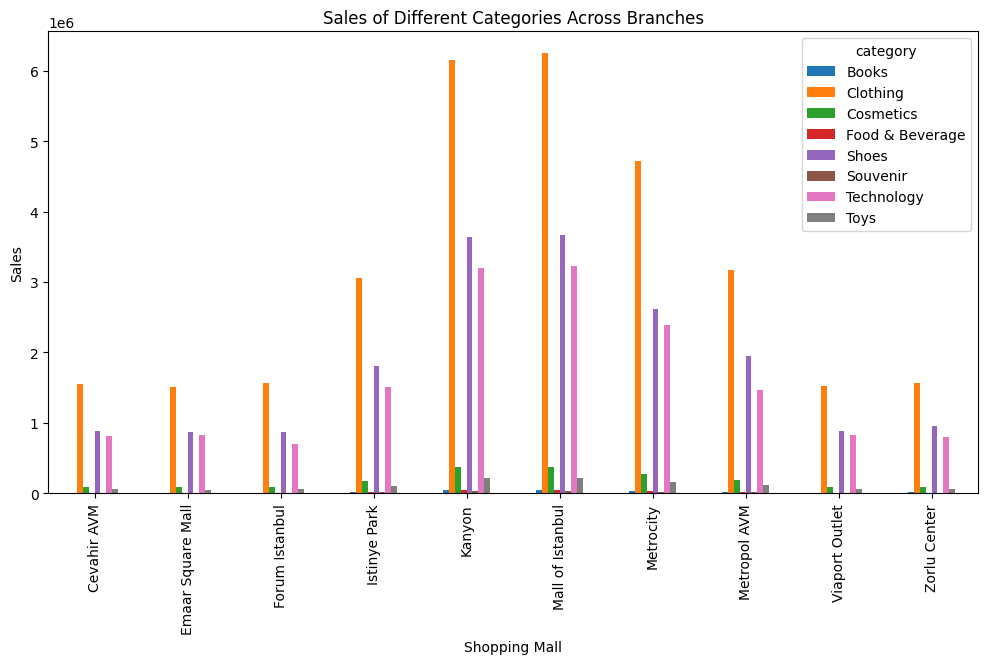

In [15]:
combined_pivot.plot(kind="bar", figsize=(12, 6))

plt.title("Sales of Different Categories Across Branches")
plt.xlabel("Shopping Mall")
plt.ylabel("Sales")
plt.show()  #Grouped bar chart for sales of different categories across branches